# 01. Completeness of the atmosphere initial states

## Purpose

Show what the ERA5 + CLIM_BASE initial file (`ERA5_CLIMFILL` EN01) holds compared with the ERA5 file of HYB_BASE EN01 (`ERA5_BARE`) and the CLIM_BASE state it is filled from. Checks: are the aerosols, ozone, other radiative gases and hydrometeor numbers present and non-zero? How large are their global means and zonal profiles (total ozone, radiative water vapour, N2O/CH4, aerosol burdens, cloud-droplet number, 50-hPa temperature)? Does the completed file keep the ERA5 fields of the same member unchanged?

**Focus: ERA5 + CLIM_BASE aerosol and ozone initialization vs the ERA5 initialization (HYB_BASE), same member.** Both runs start on 16 Dec 2011 00Z from member EN01: the same ERA5 state with the same DART perturbation EN01, over the same DATM-forced land EN01. HYB_BASE EN01 (`ERA5_BARE`) uses the ERA5 file as it is. It holds only T, U, V, Q, PS, CLDLIQ and CLDICE, and EAM starts every missing field from zero: the aerosols, ozone and the other radiative gases (`rad_climate` reads H2OLNZ, O3, N2OLNZ and CH4LNZ), and the hydrometeor numbers. `ERA5_CLIMFILL` keeps those ERA5 fields unchanged and takes every missing field from the free-running CLIM_BASE (FREE_CLIM) state of the same date (`ensemble_perturbations/util/complete_era5_ic.py`; H2OLNZ follows the ERA5 Q). The comparison `clim_fill` = ERA5_CLIMFILL − ERA5_BARE is therefore the effect of initializing aerosols, ozone and the other missing fields.

A single-member difference is judged against `ev.noise_scale`: √2 × the member spread of the 20 HYB_BASE members of the same start (`ENSEMBLE_RUN`), the chaotic divergence of two members of that ensemble. The other tests (`ERA5_DARTFILL`, `CLIMO_ATM`, `CLIMO_LND`) and production runs remain in `configs/hind_ic_test_runs.py` and can be added to `RUN_KEYS`, `PLOT_GROUPS` and `COMPARISON_KEYS`.

## Inputs and outputs

Inputs: the atmosphere initial file of every run (`configs/hind_ic_test_runs.py`, relative to `IC_ROOT`), plus the CLIM_BASE (FREE_CLIM) state.
Outputs: `data/hind_ic_test/initial_states/ic_summary.csv`, `ic_era5_field_check.csv`, `ic_zonal_means.nc`; figure `figure/hind_ic_test/initial_states/ic_zonal_means.png`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")            # production F20TR hindcasts
TEST_DATA_ROOT = Path("/pscratch/sd/z/zhan391/e3sm_dart/simulation")             # the test runs
IC_ROOT = Path("/global/cfs/cdirs/m4849/zhan391")                                  # initial-file library (DART_INIT/, e3sm_dart/)
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")                     # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"
WORKFLOW_NAME = "hind_ic_test"

RUN_KEYS = ("ERA5_BARE", "ERA5_CLIMFILL")          # HYB_BASE EN01 and ERA5 + CLIM_BASE fill EN01 (configs/hind_ic_test_runs.py)
EXTRA_STATES = ("CLIM_BASE state",)
BARE_RUN = "ERA5_BARE"                                   # the bare ERA5 file the completed files are checked against
COMPLETED_RUNS = ("ERA5_CLIMFILL",)
TOPIC = "initial_states"
FORCE_COMPUTE = False
FIGURE_DPI = 200
SHOW = True

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from util import hind_ic_test_eval as ev
from configs.hind_ic_test_runs import COMPARISONS, GROUPS, INIT, RUNS, check_runs, ensemble_members, member_dir
from util.hind_case_io import cached_dataset, cached_table, figure_saver

check_runs(RUN_KEYS)
ROOTS = {"test": TEST_DATA_ROOT, "production": INPUT_DATA_ROOT}
data_dir = DIAGNOSTIC_OUTPUT_ROOT / "data" / WORKFLOW_NAME / TOPIC
figure_dir = DIAGNOSTIC_OUTPUT_ROOT / "figure" / WORKFLOW_NAME / TOPIC
data_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)
save = figure_saver(figure_dir, dpi=FIGURE_DPI, show=SHOW)
print(f"[DATA] {data_dir}\n[FIGURE] {figure_dir}")

runs = pd.DataFrame([dict(run=k, case=f"{r.case}_{INIT.astype(object):%Y%m%d}00", member=r.member, source=r.source,
                          atmosphere=r.atm_ic, land=r.lnd_ic) for k, r in RUNS.items() if k in RUN_KEYS]).set_index("run")
display(runs)
display(pd.DataFrame([dict(comparison=k, A=a, B=b, question=q) for k, (a, b, q) in COMPARISONS.items()]).set_index("comparison"))

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/initial_states
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/initial_states


,case,member,source,atmosphere,land
run,,,,,
ERA5_BARE,F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE_2011...,EN01,production,"bare ERA5 (T, U, V, Q, PS, CLDLIQ, CLDICE only)",DATM EN01
ERA5_CLIMFILL,F20TR_ne30pg2_r05_IcoswISC30E3r5_ERA5CLIMFILL_...,EN01,test,ERA5 + CLIM_BASE fields,DATM EN01


,A,B,question
comparison,,,
clim_fill,ERA5_CLIMFILL,ERA5_BARE,ERA5 + CLIM_BASE aerosol and ozone initializat...
tracer_fix,ERA5_DARTFILL,ERA5_BARE,Does completing the ERA5 state remove the cold...
fill_source,ERA5_CLIMFILL,ERA5_DARTFILL,Does the source of the filled fields matter? (...
atm_clim,CLIMO_ATM,DA_COUPLED,"Atmosphere initial state, complete states: CLI..."
atm_bare_era5,DA_LND,DA_COUPLED,Atmosphere initial state as run in production ...
lnd_clim,CLIMO_LND,DA_COUPLED,Land initial state: CLIM_BASE - DART (both und...
lnd_datm,DA_ATM,DA_COUPLED,Land initial state as run in production DA_ATM...


## 4. Global summary of every initial file

Runs that share a file are listed together (`used by`). "Missing" names fields that are absent or zero everywhere. Burdens and columns are area-weighted global means over the dynamics columns (`area_d`). "T level" is the model level nearest the given pressure.

In [4]:
from configs.hind_ic_test_runs import ic_path

files = {}
for k in list(RUN_KEYS) + list(EXTRA_STATES):
    files.setdefault(ic_path(k, IC_ROOT).resolve(), []).append(k)
grid = ev.ic_grid(ic_path("DA_COUPLED", IC_ROOT))
stamp = "|".join(f"{p}:{p.stat().st_mtime_ns}" for p in files)


def build_summary():
    rows, zonal = [], []
    for p, keys in files.items():
        row, z = ev.ic_summary(p, grid)
        rows.append(dict(state=" / ".join(keys), **row))
        zonal.append(z.expand_dims(state=[" / ".join(keys)]))
        print(f"[IC] {' / '.join(keys)}: {p.name}")
    return pd.DataFrame(rows), xr.concat(zonal, "state")


summary_file, zonal_file = data_dir / "ic_summary.csv", data_dir / "ic_zonal_means.nc"
built = {}


def built_summary():
    """Read every file once, for both the table and the zonal means."""
    if "x" not in built:
        built["x"] = build_summary()
    return built["x"]


summary = cached_table(summary_file, lambda: built_summary()[0], stamp, force=FORCE_COMPUTE)


def zonal_build():
    ds = built_summary()[1]
    return ds.assign_coords(state=ds.state.astype(str)).rename({v: v.replace("/", " per ") for v in ds.data_vars})


zonal = cached_dataset(zonal_file, zonal_build, stamp, force=FORCE_COMPUTE)
pd.set_option("display.max_colwidth", 60)
display(summary.set_index("state").T)

[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/initial_states/ic_summary.csv
[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/initial_states/ic_zonal_means.nc


state,ERA5_BARE,ERA5_CLIMFILL,CLIM_BASE state
file,HYB_DARTPERT20.EN01.eam.i.2011-12-16-00000.nc,ERA5CLIMFILL_DARTPERT20.EN01.eam.i.2011-12-16-00000.nc,F20TR_ne30pg2_r05_IcoswISC30E3r5.FREE_CLIM.eam.i.2011-12...
state fields,7,94,94
all-zero fields,0,8,8
missing radiative gases,"H2OLNZ, O3, N2OLNZ, CH4LNZ",-,-
missing aerosols,"num_a1, so4_a1, bc_a1, dst_a1, pom_a1",-,-
missing hydrometeor numbers,"NUMLIQ, NUMICE",-,-
missing sea ice / surface,"ICEFRAC, TSICE, TS1, SNOWHICE","ICEFRAC, TSICE, TS1, SNOWHICE","ICEFRAC, TSICE, TS1, SNOWHICE"
TOZ (DU),NaN,267.732744,267.712605
column Q (kg m-2),22.828264,22.828264,24.986665
column H2OLNZ (kg m-2),NaN,22.667592,24.794615


## 5. Are the ERA5 fields unchanged in the completed files?

Maximum absolute difference from the bare ERA5 file. Zero means the completion kept the ERA5 value at every column and level.

In [5]:
def build_check():
    bare = ic_path(BARE_RUN, IC_ROOT)
    return pd.DataFrame([dict(run=k, **ev.era5_field_check(ic_path(k, IC_ROOT), bare, grid)) for k in COMPLETED_RUNS])


check = cached_table(data_dir / "ic_era5_field_check.csv", build_check, stamp, force=FORCE_COMPUTE)
display(check.set_index("run"))

[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_ic_test/initial_states/ic_era5_field_check.csv


,T,U,V,Q,PS,CLDLIQ,CLDICE
run,,,,,,,
ERA5_CLIMFILL,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 6. Zonal means

A field absent from a file is drawn as zero, the value EAM starts it from. Lines of states that share a field overlap: ERA5_BARE and ERA5_CLIMFILL in the ERA5 fields (column Q, T), ERA5_CLIMFILL and the CLIM_BASE state in the filled fields (ozone, aerosols, droplet number).


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_ic_test/initial_states/ic_zonal_means.png


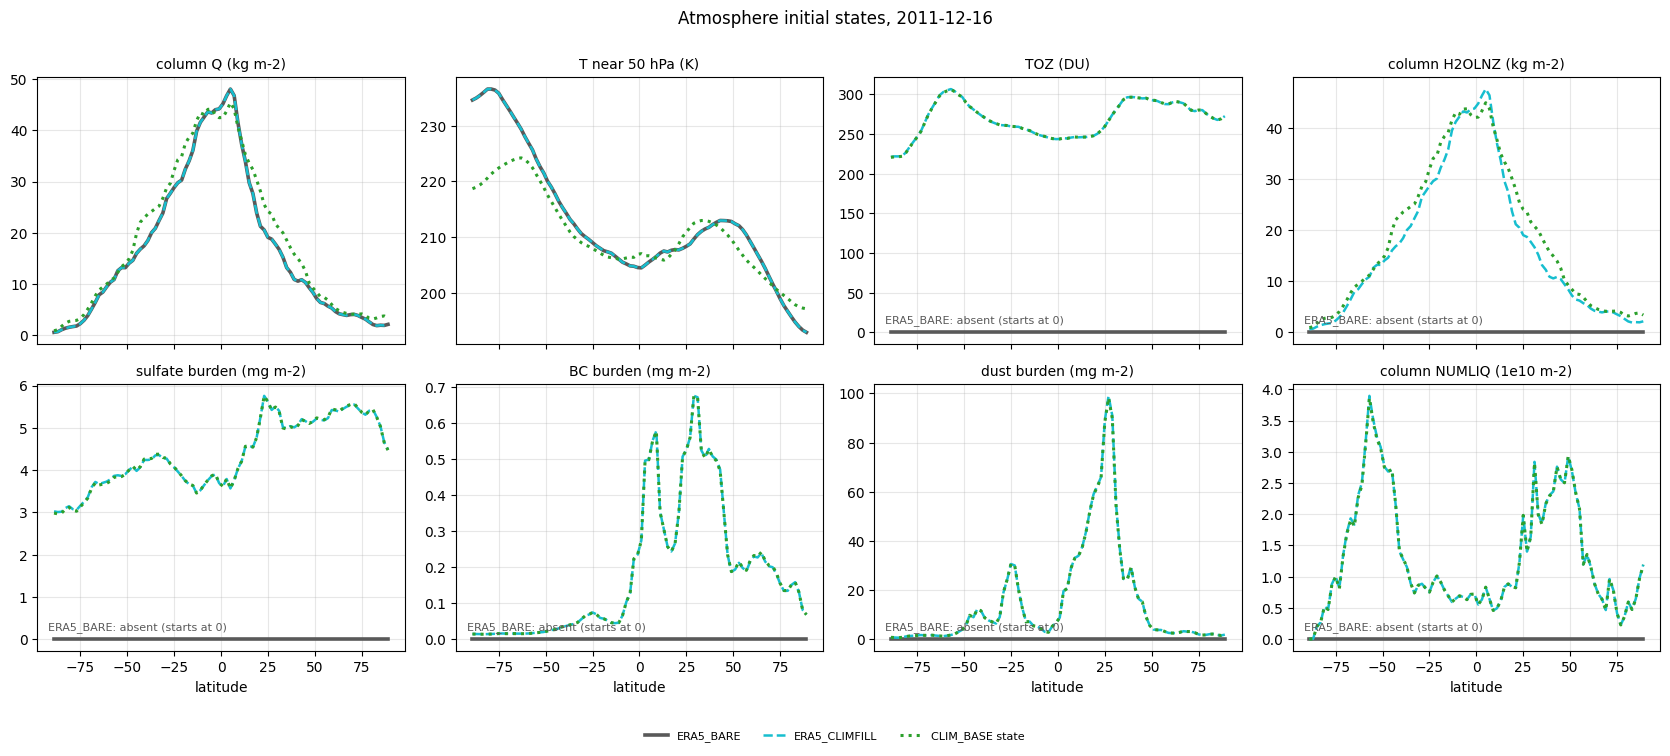

In [6]:
names = list(zonal.data_vars)
# Fixed style per state (a state skipped in one panel must not shift the colours of the others).
# A field absent from a file is drawn as zero: EAM starts it from zero.
STYLE = {"CLIM_BASE state": dict(color="tab:green", ls=":", lw=2.2)}


def style(state):
    k = state.split(" / ")[0]
    if k in RUNS:
        r = RUNS[k]
        return dict(color=r.color, ls=r.linestyle, lw=2.6 if r.linestyle == "-" else 1.8)
    return STYLE.get(k, dict(lw=1.6))


fig, axes = plt.subplots(2, (len(names) + 1) // 2, figsize=(4.2 * ((len(names) + 1) // 2), 7.0), sharex=True)
for ax, v in zip(axes.flat, names):
    for s in zonal.state.values:
        y = zonal[v].sel(state=s)
        absent = bool(y.isnull().all())
        ax.plot(zonal.lat, y.fillna(0.0) if absent else y, label=s, **style(s))
        if absent:
            ax.annotate(f"{s}: absent (starts at 0)", (0.03, 0.08), xycoords="axes fraction", fontsize=8,
                        color=style(s)["color"])
    ax.set_title(v, fontsize=10)
    ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("latitude")
for ax in list(axes.flat)[len(names):]:
    ax.axis("off")
fig.legend(*axes.flat[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=8, frameon=False,
           bbox_to_anchor=(0.5, -0.06))
fig.suptitle(f"Atmosphere initial states, {INIT}", y=1.0)
fig.tight_layout()
save(fig, "ic_zonal_means.png")
plt.show()
